# APS Failure at Scania Trucks

This notebook repurposes the structure of the Credit Risk Classification assignment for a real operational-maintenance problem.

The positive class is `pos`: a failure of the APS component in focus. The negative class is `neg`: a truck with a failure unrelated to that APS component. The model ranks trucks for inspection; it does not automatically declare a truck safe or unsafe.

**Official source:** [UCI APS Failure at Scania Trucks](https://archive.ics.uci.edu/dataset/421/aps%2Bfailure%2Bat%2Bscania%2Btrucks), DOI [10.24432/C51S51](https://doi.org/10.24432/C51S51).

**Official challenge costs:** 10 cost units for an unnecessary mechanic check and 500 cost units for missing a faulty truck. These are challenge units, not euros and not measured realised savings.

## 1. Import data and libraries

The notebook can run from the project folder. If the official CSV is not present, it downloads the official UCI archive into the relative `data/raw` directory. No personal path is required.

In [1]:
from pathlib import Path
import json
import platform
import sys
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay, average_precision_score, precision_recall_curve, roc_curve

RANDOM_STATE = 77
SOURCE_URL = 'https://archive.ics.uci.edu/static/public/421/aps%2Bfailure%2Bat%2Bscania%2Btrucks.zip'

def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / 'src' / 'data_contract.py').exists() and (candidate / 'data' / 'raw').exists():
            return candidate
    raise FileNotFoundError('Run this notebook from the scania_aps_classification project folder.')

ROOT = find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
RAW_DIR = ROOT / 'data' / 'raw'
RAW_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_PATH = RAW_DIR / 'aps_failure_training_set.csv'
OFFICIAL_TEST_PATH = RAW_DIR / 'aps_failure_test_set.csv'
ZIP_PATH = RAW_DIR / 'aps_failure_at_scania_trucks.zip'

if not TRAIN_PATH.exists() or not OFFICIAL_TEST_PATH.exists():
    request = urllib.request.Request(SOURCE_URL, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(request, timeout=180) as response, ZIP_PATH.open('wb') as handle:
        while chunk := response.read(1024 * 1024):
            handle.write(chunk)
    if ZIP_PATH.stat().st_size < 1_000_000:
        raise RuntimeError('The UCI download is unexpectedly small.')
    with zipfile.ZipFile(ZIP_PATH) as archive:
        archive.extractall(RAW_DIR)

from src.data_contract import contract_summary, load_raw_data, make_xy, validate_schema
from src.cost_policy import (
    COST_MISSED_FAILURE,
    COST_UNNECESSARY_INSPECTION,
    challenge_metrics,
    cost_sweep,
    top_k_metrics,
)
from src.evaluation import binary_metrics, evaluate_model_set
from src.models import make_candidate_models
from src.preprocessing import build_outlier_audit

print(f'Project root: {ROOT}')
print(f'Training source: {TRAIN_PATH}')
print(f'Official frozen-test source: {OFFICIAL_TEST_PATH}')
print(f'Python: {platform.python_version()}')

Project root: C:\Users\katom\iCloudDrive\Smaller Creator\Sky\Marc Torrens Group Project\scania_aps_classification
Training source: C:\Users\katom\iCloudDrive\Smaller Creator\Sky\Marc Torrens Group Project\scania_aps_classification\data\raw\aps_failure_training_set.csv
Official frozen-test source: C:\Users\katom\iCloudDrive\Smaller Creator\Sky\Marc Torrens Group Project\scania_aps_classification\data\raw\aps_failure_test_set.csv
Python: 3.14.2


## 2. Load data, define the target and split before fitting anything

The UCI files contain a 20-line licence preamble, which is skipped by the data contract. Missing values are encoded as `na` and become `NaN`.

The UCI archive supplies separate labelled training and test files. The full labelled training file is used for development out-of-fold model and threshold selection. The separate labelled official test file is kept untouched and used once for final confirmation.

In [2]:
training_frame = load_raw_data(TRAIN_PATH)
official_test_frame = load_raw_data(OFFICIAL_TEST_PATH)
print('Training-data preview:')
display(training_frame.head())
print(f'Training shape: {training_frame.shape}; official test shape: {official_test_frame.shape}')
validate_schema(training_frame, require_full_training_size=True)
validate_schema(official_test_frame)
X_dev, y_dev = make_xy(training_frame)
X_test, y_test = make_xy(official_test_frame)
X_dev = X_dev.astype('float32')
X_test = X_test.astype('float32')

split_report = pd.DataFrame({
    'split': ['labelled development/training', 'official frozen test'],
    'rows': [len(y_dev), len(y_test)],
    'positive APS failures': [int(y_dev.sum()), int(y_test.sum())],
    'positive rate': [y_dev.mean(), y_test.mean()],
})
display(split_report)
print('The positive class is APS component failure; the negative class is an unrelated component failure.')

Training-data preview:


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


Training shape: (60000, 171); official test shape: (16000, 171)


,split,rows,positive APS failures,positive rate
0,labelled development/training,60000,1000,0.016667
1,official frozen test,16000,375,0.023438


The positive class is APS component failure; the negative class is an unrelated component failure.


## 3. Data contract and context

One row represents one selected truck operating example. The anonymised variables are operational counters and histogram bins. The public data does not provide a future time horizon, maintenance outcome, or causal proof that an inspection prevented a breakdown. Therefore, the target is a benchmark classification label, not a directly observed “failure in the next 12 months” outcome.

In [3]:
training_summary = contract_summary(training_frame)
test_summary = contract_summary(official_test_frame)
contract_table = pd.DataFrame([
    {'dataset': 'labelled development/training', 'check': check, 'result': value}
    for check, value in training_summary.items()
] + [
    {'dataset': 'official frozen test', 'check': check, 'result': value}
    for check, value in test_summary.items()
])
display(contract_table)
assert training_summary['rows'] == 60_000
assert training_summary['features'] == 170
assert training_summary['positive_failures'] == 1_000
assert test_summary['rows'] == 16_000
assert test_summary['positive_failures'] == 375

,dataset,check,result
0,labelled development/training,rows,60000.000000
1,labelled development/training,columns,171.000000
2,labelled development/training,features,170.000000
3,labelled development/training,positive_failures,1000.000000
4,labelled development/training,negative_unrelated_failures,59000.000000
5,labelled development/training,positive_rate,0.016667
6,labelled development/training,missing_cells,850015.000000
7,labelled development/training,duplicate_rows,0.000000
8,labelled development/training,constant_features,0.000000
9,official frozen test,rows,16000.000000


## 4. Data cleaning and missingness audit

Missing sensor values are part of the operational-data problem. We do not delete rows or fill values using the whole dataset. Median imputation and missingness indicators are fitted inside each model pipeline using development data only. Duplicate rows and constant predictors are checked before modelling.

Outliers are detected feature by feature on development data. Approximately symmetric features use a z-score bound of +/-3 standard deviations. Skewed/non-normal features use Tukey's IQR rule (1.5 x IQR). We cap extreme values inside each training fold rather than deleting trucks; the official test remains untouched until confirmation.

,check,count
0,missing cells,850015
1,duplicate rows,0
2,constant predictors,0
3,positive label count,1000


,missing share
br_000,0.821067
bq_000,0.812033
bp_000,0.795667
bo_000,0.772217
ab_000,0.772150
cr_000,0.772150
bn_000,0.733483
bm_000,0.659150
bl_000,0.454617
bk_000,0.383900


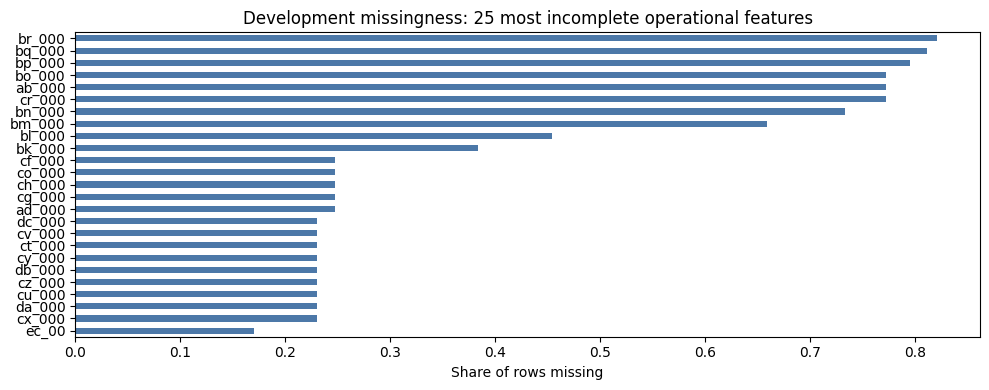

,feature,skewness,distribution_rule,method,lower_bound,upper_bound,observed_values,flagged_count,flagged_rate
0,bn_000,1.137405,skewed/non-normal,IQR,-310350.0,975170.0,15991,3509,0.219436
1,ba_008,53.345250,skewed/non-normal,IQR,-2730.0,4550.0,59312,12580,0.212099
2,dy_000,20.747663,skewed/non-normal,IQR,-54.0,90.0,57276,11867,0.207190
3,dx_000,10.871086,skewed/non-normal,IQR,-13146.0,21910.0,57277,11572,0.202036
4,ag_009,98.288989,skewed/non-normal,IQR,-546.0,910.0,59329,11926,0.201015
5,ba_009,49.209881,skewed/non-normal,IQR,-90.0,150.0,59312,11582,0.195272
6,cl_000,19.787630,skewed/non-normal,IQR,-3.0,5.0,50447,9703,0.192340
7,cm_000,15.499523,skewed/non-normal,IQR,-150.0,250.0,50123,9594,0.191409
8,ee_009,29.214135,skewed/non-normal,IQR,-3042.0,5070.0,59329,11316,0.190733
9,ac_000,1.784845,skewed/non-normal,IQR,-1406.0,2386.0,56665,10800,0.190594


,method,features,flagged_values,average_flagged_rate
0,IQR,118,702961,0.106951
1,none,46,0,0.000000
2,z-score,6,0,0.000000


<Figure size 1000x400 with 0 Axes>

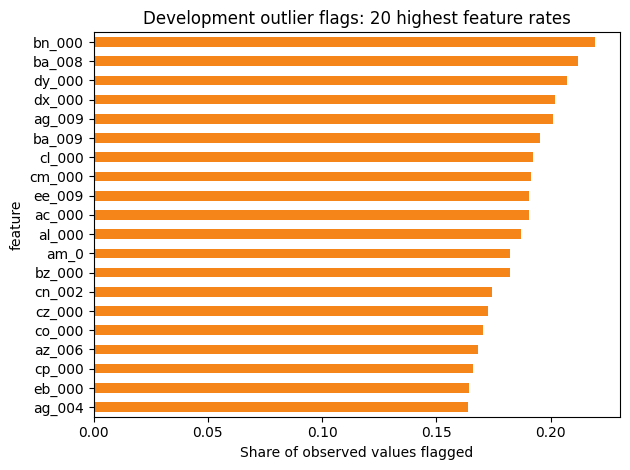

In [4]:
cleaning_report = pd.DataFrame({
    'check': ['missing cells', 'duplicate rows', 'constant predictors', 'positive label count'],
    'count': [
        int(X_dev.isna().sum().sum()),
        int(training_frame.duplicated().sum()),
        int((X_dev.nunique(dropna=False) <= 1).sum()),
        int(y_dev.sum()),
    ],
})
display(cleaning_report)

FIGURES = ROOT / 'figures'
TABLES = ROOT / 'artifacts' / 'tables'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

missingness = X_dev.isna().mean().sort_values(ascending=False)
display(missingness.head(15).rename('missing share').to_frame())
plt.figure(figsize=(10, 4))
missingness.head(25).sort_values().plot.barh(color='#4c78a8')
plt.title('Development missingness: 25 most incomplete operational features')
plt.xlabel('Share of rows missing')
plt.tight_layout()
plt.savefig(FIGURES / 'missingness.png', dpi=160)
plt.show()

outlier_audit = build_outlier_audit(X_dev)
display(outlier_audit.head(15))
display(outlier_audit.groupby('method', dropna=False).agg(
    features=('feature', 'count'),
    flagged_values=('flagged_count', 'sum'),
    average_flagged_rate=('flagged_rate', 'mean'),
).reset_index())
outlier_audit.to_csv(TABLES / 'outlier-audit.csv', index=False)
plt.figure(figsize=(10, 4))
outlier_audit.head(20).sort_values('flagged_rate').plot.barh(
    x='feature', y='flagged_rate', legend=False, color='#f58518'
)
plt.title('Development outlier flags: 20 highest feature rates')
plt.xlabel('Share of observed values flagged')
plt.tight_layout()
plt.savefig(FIGURES / 'outlier-flags.png', dpi=160)
plt.show()
del training_frame, official_test_frame

## 5. Candidate models and leakage-safe pipelines

The same comparison logic is retained from the credit-risk assignment: a majority baseline, logistic regression, a decision tree and a random forest. The rare positive class requires class weighting for the non-baseline candidates. Outlier clipping, imputation, missingness indicators and scaling are inside the pipeline, so cross-validation cannot learn from the validation fold.

In [5]:
models = make_candidate_models(list(X_dev.columns), random_state=RANDOM_STATE)
print('Candidate models:', list(models))

Candidate models: ['majority_baseline', 'logistic_regression', 'decision_tree', 'random_forest']


## 6. Fit, compare and select using development out-of-fold predictions

ROC-AUC and average precision measure ranking quality. The Scania decision criterion is total challenge cost: false positives cost 10, while false negatives cost 500. The official frozen test is not used to select the model.

In [6]:
comparison, predictions, fitted_models = evaluate_model_set(
    models,
    X_dev,
    y_dev,
    X_test,
    y_test,
    random_state=RANDOM_STATE,
)

development_rows = []
for model_name in models:
    score = predictions[model_name]['development']
    sweep = cost_sweep(y_dev, score, np.linspace(0.001, 0.999, 200))
    best = sweep.sort_values(['total_cost', 'fn', 'fp']).iloc[0]
    metric_row = comparison.query("model == @model_name and split == 'development OOF'").iloc[0]
    development_rows.append({
        'model': model_name,
        'ROC-AUC': metric_row['roc_auc'],
        'average precision': metric_row['average_precision'],
        'best development threshold': best['threshold'],
        'development total cost': best['total_cost'],
        'development cost avoided': best['cost_avoided_vs_all_negative'],
        'inspections at best threshold': best['inspections'],
    })
model_selection = pd.DataFrame(development_rows).sort_values(
    ['development total cost', 'average precision'], ascending=[True, False]
).reset_index(drop=True)
display(model_selection)
selected_model = model_selection.iloc[0]['model']
selected_dev_score = predictions[selected_model]['development']
selected_test_score = predictions[selected_model]['frozen_test']
print(f'Selected model from development cost: {selected_model}')
model_selection.to_csv(TABLES / 'model-selection.csv', index=False)

,model,ROC-AUC,average precision,best development threshold,development total cost,development cost avoided,inspections at best threshold
0,random_forest,0.982844,0.704805,0.141422,46220.0,453780.0,3939.0
1,logistic_regression,0.968094,0.667661,0.206618,67900.0,432100.0,4373.0
2,decision_tree,0.931603,0.567011,0.662990,82280.0,417720.0,3312.0
3,majority_baseline,0.500000,0.016667,0.021060,500000.0,0.0,0.0


Selected model from development cost: random_forest


## 7. Frozen-test discrimination: ROC-AUC and precision-recall

These curves show the model’s ranking behaviour over many possible cutoffs. They are not one selected threshold. Average precision should be compared with the positive-class base rate, because the class is highly imbalanced.

Frozen-test ROC-AUC: 0.9894
Frozen-test average precision: 0.8161
Frozen-test positive base rate: 0.0234


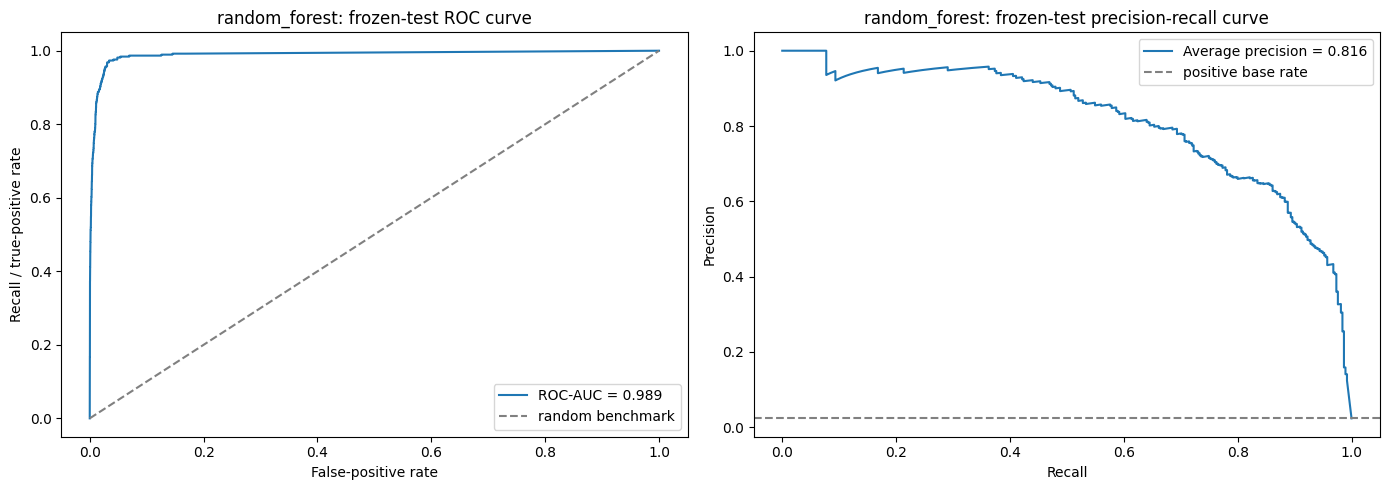

In [7]:
from sklearn.metrics import average_precision_score, roc_auc_score

test_metrics = binary_metrics(y_test, selected_test_score, threshold=0.5)
print(f"Frozen-test ROC-AUC: {test_metrics['roc_auc']:.4f}")
print(f"Frozen-test average precision: {test_metrics['average_precision']:.4f}")
print(f"Frozen-test positive base rate: {y_test.mean():.4f}")

fpr, tpr, _ = roc_curve(y_test, selected_test_score)
precision, recall, _ = precision_recall_curve(y_test, selected_test_score)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(fpr, tpr, label=f"ROC-AUC = {test_metrics['roc_auc']:.3f}")
axes[0].plot([0, 1], [0, 1], '--', color='grey', label='random benchmark')
axes[0].set(xlabel='False-positive rate', ylabel='Recall / true-positive rate', title=f'{selected_model}: frozen-test ROC curve')
axes[0].legend()
axes[1].plot(recall, precision, label=f"Average precision = {test_metrics['average_precision']:.3f}")
axes[1].axhline(y_test.mean(), linestyle='--', color='grey', label='positive base rate')
axes[1].set(xlabel='Recall', ylabel='Precision', title=f'{selected_model}: frozen-test precision-recall curve')
axes[1].legend()
plt.tight_layout()
plt.savefig(FIGURES / 'roc-pr-curves.png', dpi=160)
plt.show()

## 8. Six operating points and the required cost table

A threshold is the score cutoff for sending a truck to inspection. Lowering it usually captures more positive failures but sends more unrelated-failure trucks to a mechanic. Because the UCI case does not specify a real inspection capacity, the 10% point below is explicitly an illustrative capacity scenario, not a Scania fact.

In [8]:
dev_sweep = cost_sweep(y_dev, selected_dev_score, np.linspace(0.001, 0.999, 400))
cost_optimal_threshold = float(dev_sweep.sort_values(['total_cost', 'fn', 'fp']).iloc[0]['threshold'])

def threshold_for_recall(y_true, score, target=0.90):
    candidates = np.unique(np.round(score, 6))
    rows = [challenge_metrics(y_true, score, float(t)) for t in candidates]
    eligible = [row for row in rows if row['recall'] >= target and row['inspections'] > 0]
    return float(max(eligible, key=lambda row: row['threshold'])['threshold']) if eligible else float(np.quantile(score, 0.20))

def threshold_for_precision(y_true, score, target=0.80, min_inspections=25):
    candidates = np.unique(np.round(score, 6))
    rows = [challenge_metrics(y_true, score, float(t)) for t in candidates]
    eligible = [row for row in rows if row['precision'] >= target and row['inspections'] >= min_inspections]
    return float(min(eligible, key=lambda row: row['threshold'])['threshold']) if eligible else float(np.quantile(score, 0.95))

high_recall_threshold = threshold_for_recall(y_dev, selected_dev_score)
high_precision_threshold = threshold_for_precision(y_dev, selected_dev_score)
mid_threshold = 0.20
capacity_fraction = 0.10
capacity_threshold = float(np.quantile(selected_dev_score, 1 - capacity_fraction))

points = [
    {'name': 'default threshold 0.50', 'threshold': 0.50, 'reason': 'Required reference point where meaningful'},
    {'name': 'high-recall point', 'threshold': high_recall_threshold, 'reason': 'Development threshold targeting at least 90% recall'},
    {'name': 'mid-range point', 'threshold': mid_threshold, 'reason': 'Additional operating point'},
    {'name': 'high-precision point', 'threshold': high_precision_threshold, 'reason': 'Development threshold targeting at least 80% precision where feasible'},
    {'name': 'cost-aware point', 'threshold': cost_optimal_threshold, 'reason': 'Lowest development challenge cost'},
    {'name': 'capacity-constrained ranking point', 'threshold': capacity_threshold, 'reason': 'Illustrative top-10% inspection capacity'},
]

table_rows = []
for point in points:
    row = challenge_metrics(y_test, selected_test_score, point['threshold'])
    row.update({'operating point': point['name'], 'threshold rule': f"score >= {point['threshold']:.6f}", 'reason': point['reason']})
    table_rows.append(row)
capacity_test = top_k_metrics(y_test, selected_test_score, capacity_fraction)
capacity_test.update({'operating point': 'capacity-constrained exact top-10%', 'threshold rule': 'rank highest 10% exactly', 'reason': 'Exact capacity policy; boundary score is diagnostic'})
threshold_table = pd.DataFrame(table_rows + [capacity_test])
threshold_table = threshold_table[[
    'operating point', 'threshold rule', 'reason', 'inspections', 'inspection_rate', 'tp', 'fp', 'fn', 'tn',
    'precision', 'recall', 'f1', 'unnecessary_inspection_cost', 'missed_failure_cost', 'total_cost',
    'all_negative_baseline_cost', 'cost_avoided_vs_all_negative'
]]
display(threshold_table)
threshold_table.to_csv(TABLES / 'frozen-test-threshold-table.csv', index=False)

,operating point,threshold rule,reason,inspections,inspection_rate,tp,fp,fn,tn,precision,recall,f1,unnecessary_inspection_cost,missed_failure_cost,total_cost,all_negative_baseline_cost,cost_avoided_vs_all_negative
0,default threshold 0.50,score >= 0.500000,Required reference point where meaningful,523,0.032688,326,197,49,15428,0.623327,0.869333,0.726058,1970.0,24500.0,26470.0,187500.0,161030.0
1,high-recall point,score >= 0.310875,Development threshold targeting at least 90% r...,744,0.046500,353,391,22,15234,0.474462,0.941333,0.630920,3910.0,11000.0,14910.0,187500.0,172590.0
2,mid-range point,score >= 0.200000,Additional operating point,925,0.057813,365,560,10,15065,0.394595,0.973333,0.561538,5600.0,5000.0,10600.0,187500.0,176900.0
3,high-precision point,score >= 0.810244,Development threshold targeting at least 80% p...,222,0.013875,194,28,181,15597,0.873874,0.517333,0.649916,280.0,90500.0,90780.0,187500.0,96720.0
4,cost-aware point,score >= 0.146073,Lowest development challenge cost,1041,0.065062,366,675,9,14950,0.351585,0.976000,0.516949,6750.0,4500.0,11250.0,187500.0,176250.0
5,capacity-constrained ranking point,score >= 0.038483,Illustrative top-10% inspection capacity,1571,0.098187,370,1201,5,14424,0.235519,0.986667,0.380267,12010.0,2500.0,14510.0,187500.0,172990.0
6,capacity-constrained exact top-10%,rank highest 10% exactly,Exact capacity policy; boundary score is diagn...,1600,0.100000,370,1230,5,14395,0.231250,0.986667,0.374684,12300.0,2500.0,14800.0,187500.0,172700.0


**How to read the table:** `total cost = 10 × false positives + 500 × false negatives`. The recommended policy is selected from development evidence, then reported once on the official frozen test. The exact top-10% row is a capacity policy; its displayed boundary score is not itself the deployment rule.

Recommended policy: random_forest, score >= 0.146073.
Frozen-test total challenge cost: 11250 units.
Frozen-test cost avoided versus inspecting nobody: 176250 units.
This is conditional benchmark arithmetic, not measured savings or proof of causal breakdown prevention.


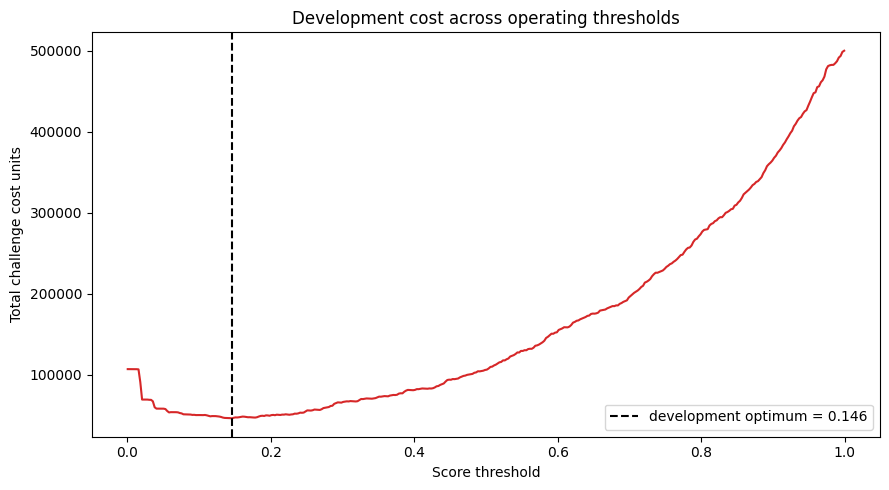

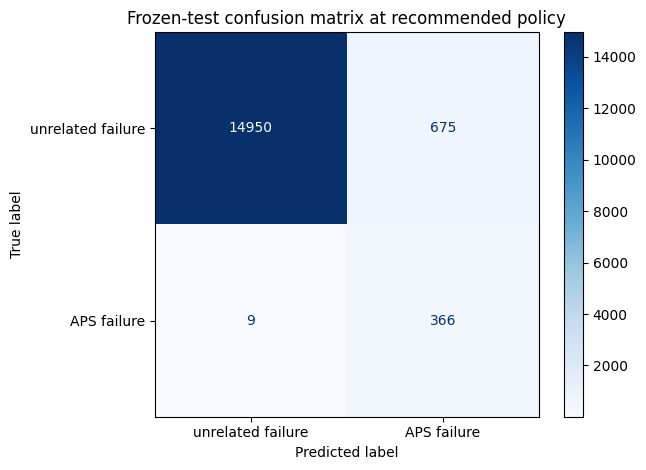

In [9]:
recommended_name = 'cost-aware point'
recommended_row = threshold_table.loc[threshold_table['operating point'].eq(recommended_name)].iloc[0]
print(f"Recommended policy: {selected_model}, score >= {recommended_row['threshold rule'].split('>=')[-1].strip()}.")
print(f"Frozen-test total challenge cost: {recommended_row['total_cost']:.0f} units.")
print(f"Frozen-test cost avoided versus inspecting nobody: {recommended_row['cost_avoided_vs_all_negative']:.0f} units.")
print('This is conditional benchmark arithmetic, not measured savings or proof of causal breakdown prevention.')

plt.figure(figsize=(9, 5))
plt.plot(dev_sweep['threshold'], dev_sweep['total_cost'], color='#d62728')
plt.axvline(cost_optimal_threshold, linestyle='--', color='black', label=f'development optimum = {cost_optimal_threshold:.3f}')
plt.xlabel('Score threshold')
plt.ylabel('Total challenge cost units')
plt.title('Development cost across operating thresholds')
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES / 'cost-by-threshold.png', dpi=160)
plt.show()

ConfusionMatrixDisplay.from_predictions(
    y_test,
    (selected_test_score >= float(recommended_row['threshold rule'].split('>=')[-1])).astype(int),
    display_labels=['unrelated failure', 'APS failure'],
    cmap='Blues',
)
plt.title('Frozen-test confusion matrix at recommended policy')
plt.tight_layout()
plt.savefig(FIGURES / 'recommended-confusion-matrix.png', dpi=160)
plt.show()

## 9. Sensitivity analysis

Sensitivity changes the economic assumptions, not the model’s predictions. The base case uses the official challenge costs. The other cases show whether the recommendation is still attractive if the cost of a missed failure or an unnecessary inspection changes. All values remain challenge cost units.

In [10]:
recommended_threshold = float(recommended_row['threshold rule'].split('>=')[-1])
scenarios = [
    {'scenario': 'official base', 'cost_fp': 10, 'cost_fn': 500},
    {'scenario': 'lower missed-failure cost', 'cost_fp': 10, 'cost_fn': 350},
    {'scenario': 'severe missed-failure cost', 'cost_fp': 10, 'cost_fn': 750},
    {'scenario': 'expensive inspection', 'cost_fp': 50, 'cost_fn': 500},
]
sensitivity_rows = []
for scenario in scenarios:
    row = challenge_metrics(y_test, selected_test_score, recommended_threshold, scenario['cost_fp'], scenario['cost_fn'])
    row.update(scenario)
    sensitivity_rows.append(row)
sensitivity_table = pd.DataFrame(sensitivity_rows)[[
    'scenario', 'cost_fp', 'cost_fn', 'inspections', 'tp', 'fp', 'fn', 'precision', 'recall', 'total_cost', 'cost_avoided_vs_all_negative'
]]
display(sensitivity_table)
sensitivity_table.to_csv(TABLES / 'sensitivity-analysis.csv', index=False)

capacity_rows = []
for fraction in [0.05, 0.10, 0.20, 0.30]:
    row = top_k_metrics(y_test, selected_test_score, fraction)
    row['capacity'] = f'top {fraction:.0%}'
    capacity_rows.append(row)
capacity_table = pd.DataFrame(capacity_rows)
display(capacity_table[['capacity', 'inspections', 'tp', 'fp', 'fn', 'precision', 'recall', 'total_cost', 'cost_avoided_vs_all_negative']])
capacity_table.to_csv(TABLES / 'capacity-sensitivity.csv', index=False)

,scenario,cost_fp,cost_fn,inspections,tp,fp,fn,precision,recall,total_cost,cost_avoided_vs_all_negative
0,official base,10,500,1041,366,675,9,0.351585,0.976,11250.0,176250.0
1,lower missed-failure cost,10,350,1041,366,675,9,0.351585,0.976,9900.0,121350.0
2,severe missed-failure cost,10,750,1041,366,675,9,0.351585,0.976,13500.0,267750.0
3,expensive inspection,50,500,1041,366,675,9,0.351585,0.976,38250.0,149250.0


,capacity,inspections,tp,fp,fn,precision,recall,total_cost,cost_avoided_vs_all_negative
0,top 5%,800,359,441,16,0.44875,0.957333,12410.0,175090.0
1,top 10%,1600,370,1230,5,0.23125,0.986667,14800.0,172700.0
2,top 20%,3200,372,2828,3,0.11625,0.992000,29780.0,157720.0
3,top 30%,4800,372,4428,3,0.07750,0.992000,45780.0,141720.0


## 10. Governance and operational subgroup audit

The predictors are anonymised operational variables; the public dataset does not provide protected-group attributes. Therefore this is not a fairness certification. As an audit-only diagnostic, we compare trucks with higher versus lower missingness burden. The grouping is defined from development data and is not used for model or threshold selection.

In [11]:
dev_missing_cut = X_dev.isna().mean(axis=1).quantile(0.75)
test_missing_share = X_test.isna().mean(axis=1)
audit_group = np.where(test_missing_share >= dev_missing_cut, 'higher missingness burden', 'lower missingness burden')
audit_rows = []
for group in ['lower missingness burden', 'higher missingness burden']:
    mask = audit_group == group
    metrics = challenge_metrics(y_test[mask], selected_test_score[mask], recommended_threshold)
    metrics.update({'audit_group': group, 'rows': int(mask.sum()), 'positive_rate': float(y_test[mask].mean())})
    audit_rows.append(metrics)
subgroup_audit = pd.DataFrame(audit_rows)
display(subgroup_audit[['audit_group', 'rows', 'positive_rate', 'inspections', 'inspection_rate', 'tp', 'fp', 'fn', 'tn', 'precision', 'recall']])
subgroup_audit.to_csv(TABLES / 'operational-subgroup-audit.csv', index=False)
print('Audit-only diagnostic: no protected attributes are available, and this table is not a fairness certification.')

,audit_group,rows,positive_rate,inspections,inspection_rate,tp,fp,fn,tn,precision,recall
0,lower missingness burden,11953,0.007948,362,0.030285,90,272,5,11586,0.248619,0.947368
1,higher missingness burden,4047,0.069187,679,0.167779,276,403,4,3364,0.406480,0.985714


Audit-only diagnostic: no protected attributes are available, and this table is not a fairness certification.


## 11. Reproducibility and limitations

The run uses random seed 77, development out-of-fold predictions on the full labelled training file for model/policy selection, and one confirmation on the separate labelled official test file. Outlier bounds, imputation values and scaling parameters are fitted inside each development fold. The official test file is never used to fit preprocessing, select the model or tune the threshold.

The target is a benchmark class label, not a future failure horizon. Before real deployment, validate timestamp availability, prospective failure outcomes, inspection effectiveness, operational drift, alarm fatigue and whether the model changes maintenance decisions safely. Human maintenance oversight remains required.

In [12]:
comparison.to_csv(TABLES / 'model-metrics-development-and-frozen.csv', index=False)
split_report.to_csv(TABLES / 'split-report.csv', index=False)
contract_table.to_csv(TABLES / 'data-contract-summary.csv', index=False)

manifest = {
    'dataset': 'UCI APS Failure at Scania Trucks',
    'source_url': 'https://archive.ics.uci.edu/dataset/421/aps%2Bfailure%2Bat%2Bscania%2Btrucks',
    'doi': '10.24432/C51S51',
    'random_state': RANDOM_STATE,
    'split': '60,000 labelled training rows for development; 16,000 labelled official test rows for frozen confirmation',
    'selected_model': selected_model,
    'recommended_policy': 'development cost-aware threshold, confirmed once on official frozen test',
    'outlier_policy': 'feature-wise z-score +/-3 for approximately symmetric features; Tukey IQR 1.5x for skewed/non-normal features; clip inside each training fold',
    'cost_unnecessary_inspection': COST_UNNECESSARY_INSPECTION,
    'cost_missed_failure': COST_MISSED_FAILURE,
    'python': platform.python_version(),
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'sklearn': __import__('sklearn').__version__,
}
(ROOT / 'artifacts').mkdir(exist_ok=True)
(ROOT / 'artifacts' / 'run-manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
print(json.dumps(manifest, indent=2))

{
  "dataset": "UCI APS Failure at Scania Trucks",
  "source_url": "https://archive.ics.uci.edu/dataset/421/aps%2Bfailure%2Bat%2Bscania%2Btrucks",
  "doi": "10.24432/C51S51",
  "random_state": 77,
  "split": "60,000 labelled training rows for development; 16,000 labelled official test rows for frozen confirmation",
  "selected_model": "random_forest",
  "recommended_policy": "development cost-aware threshold, confirmed once on official frozen test",
  "outlier_policy": "feature-wise z-score +/-3 for approximately symmetric features; Tukey IQR 1.5x for skewed/non-normal features; clip inside each training fold",
  "cost_unnecessary_inspection": 10.0,
  "cost_missed_failure": 500.0,
  "python": "3.14.2",
  "pandas": "2.3.3",
  "numpy": "2.4.1",
  "sklearn": "1.8.0"
}


## Conclusion

The final recommendation is a cost-sensitive inspection-prioritisation policy. It ranks trucks by APS-failure score and uses a threshold selected on development data to reduce the much larger cost of missed failures. The result is a benchmark decision aid, not an automatic maintenance decision and not proof of realised savings.